In [1]:
import numpy as np
import scipy as sp
import sympy as smp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../../')

import oasis_dla

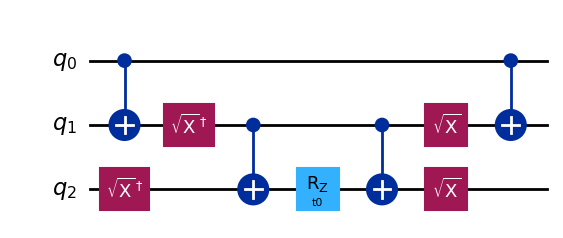

In [2]:
vqls_rz = oasis_dla.VQLS(qubits=3, ansatz_type=1)
vqls_ry = oasis_dla.VQLS(qubits=3, ansatz_type=0)

ansatz = qiskit.QuantumCircuit(3)
param = qiskit.circuit.Parameter('t0')
ansatz.cx(0, 1)
ansatz.ryy(param, 1, 2)
ansatz.cx(0, 1)

vqls = oasis_dla.VQLS(qubits=3, optimizer="COBYQA", ansatz=ansatz)

display(vqls.ansatz.decompose().draw('mpl'))
# display(vqls_ry.ansatz.draw('mpl'))
# display(vqls_rz.ansatz.draw('mpl'))

In [ ]:
A_0 = np.eye(8) # 2^3
A_1 = 0.2 * np.kron(np.kron(oasis_dla.X, oasis_dla.Z), np.eye(2))
A_2 = 0.2 * np.kron(np.kron(oasis_dla.X, np.eye(2)), np.eye(2))
A = A_0 + A_1 + A_2

# data = vqls.generate_dataset(random_entries=[1+0j, 2+0j, 3+0j, 4+0j], shots=1)
# display(smp.Matrix(data[0]))
# print(data[0].shape)

A = np.random.rand(8, 8)
b = np.ones(8) / np.sqrt(8)

print(A)
vqls.solve(A, b)

[[0.40830228 0.73725089 0.36046043 0.79590754 0.02979933 0.51355783
  0.92143691 0.04339754]
 [0.04061396 0.98693577 0.98752249 0.14104839 0.15429518 0.38448664
  0.96766776 0.41987058]
 [0.76439333 0.12801146 0.01746663 0.73302133 0.59885988 0.32224244
  0.27840436 0.57243157]
 [0.15591932 0.41448332 0.90121375 0.90915874 0.38713983 0.4676566
  0.16017522 0.69847053]
 [0.51400255 0.82215285 0.87298189 0.86387401 0.33732009 0.62153811
  0.70110946 0.18277086]
 [0.89172699 0.74746553 0.82546493 0.8321013  0.64883842 0.98067089
  0.25768983 0.46954223]
 [0.9003461  0.87002443 0.50239261 0.31664744 0.02979462 0.91592231
  0.52547705 0.91953671]
 [0.19353504 0.13344107 0.83949833 0.65950177 0.14049285 0.66756182
  0.91802617 0.17060296]]
Solving
Optimizing
 fun: 0.16610516900991346
   x: [ 1.982e-01]
 fun: 0.15794818907543762
   x: [ 1.198e+00]
 fun: 0.15794818907543762
   x: [ 1.198e+00]
 fun: 0.1479302594328622
   x: [ 2.198e+00]
 fun: 0.14432674105070248
   x: [ 3.198e+00]
 fun: 0.14432

In [ ]:
np.linalg.solve(A, b)
# accuracies, t_times = vqls_rz.accuracy_test(data)

array([-0.53075126,  0.59952339,  0.98979703,  1.36887969, -1.0654826 ,
        0.73499576, -1.13408695, -0.76239354])